In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt

Get data

In [ ]:
# Generate synthetic by using Scikit-learn tool
X, Y = make_classification(
  n_samples=1000, n_features=4, n_redundant=0,
  n_informative=3,  n_clusters_per_class=2, n_classes=3
)

X_train, X_test, Y_train, Y_test = train_test_split(
  X, Y, test_size=0.33, random_state=42)

In [ ]:
# Creating Dataset and Dataloader
class Data(Dataset):
  def __init__(self, X_train, y_train):
    self.features = torch.from_numpy(X_train.astype(np.float32))
    self.labels = torch.from_numpy(y_train).type(torch.LongTensor)

  def __getitem__(self, index):
    return self.features[index], self.labels[index]

  def __len__(self):
    return self.features.shape[0]

batch_size = 10

traindata = Data(X_train, Y_train)
trainloader = DataLoader(traindata, batch_size=batch_size,
                         shuffle=True, num_workers=2)
testdata = Data(X_test, Y_test)
testloader = DataLoader(traindata, batch_size=batch_size,
                         shuffle=True, num_workers=2)

### Crear el modelo
Creen un modelo con tres capas: 1 de entrada, 1 intermedia y 1 de salida.


In [ ]:
# Creen un modelo con tres capas: 1 de entrada, 1 intermedia y 1 de salida.
class Network(nn.Module):
  def __init__(self, input_dim, hidden_dim, output_dim):
    super(Network, self).__init__()
    self.linear1 = nn.Linear(input_dim, hidden_dim)
    self.relu = nn.ReLU()
    self.linear2 = nn.Linear(hidden_dim, output_dim)
    self.softmax = nn.Softmax(dim=1)
  def forward(self, x):
    x = self.linear1(x)
    x = self.relu(x)
    x = self.linear2(x)
    x = self.softmax(x)
    return x


### Configurar el entrenamiento
Elijan una función de pérdida para un clasificador multicapa

In [ ]:
# number of features (len of X cols)
input_dim = 4
# number of hidden layers
hidden_dim = 40
# number of classes (unique of y)
output_dim = 3
classifier = Network(input_dim, hidden_dim, output_dim)
criterion = nn.CrossEntropyLoss()
learning_rate = 0.1
optimizer = torch.optim.SGD(classifier.parameters(), lr=learning_rate)

### Llevar a cabo el entrenamiento

In [ ]:
classifier.train()

epochs = 100
losses = []
accuracies = []
for epoch in range(epochs):
  # Variables to get stats
  running_loss = 0.0
  total_samples = 0
  correct_predictions = 0
  for i, (inputs, labels) in enumerate(trainloader, 0):
    # set optimizer to zero grad to remove previous epoch gradients
    optimizer.zero_grad()
    # forward propagation
    y_pred = classifier(inputs)
    loss = criterion(y_pred, labels)
    # backward propagation
    loss.backward()
    # optimize
    optimizer.step()

    # Storing losses
    running_loss += loss.item()

    # Accuracy calculation
    _, predicted = torch.max(y_pred.data, 1) # Get the labels
    total_samples += labels.size(0)
    correct_predictions += (predicted == labels).sum().item()

  # Calculate and store average loss after each epoch
  avg_loss = running_loss / len(trainloader)
  losses.append(avg_loss)

  # Calculate and store accuracy after each epoch
  accuracy = correct_predictions / total_samples
  accuracies.append(accuracy)

  # Print stats
  print(f'[Epoch: {epoch + 1}] loss: {avg_loss :.5f} - accuracy: {accuracy}')

[Epoch: 1] loss: 0.97353 - accuracy: 0.6179104477611941
[Epoch: 2] loss: 0.85167 - accuracy: 0.7507462686567165
[Epoch: 3] loss: 0.80740 - accuracy: 0.7716417910447761
[Epoch: 4] loss: 0.78132 - accuracy: 0.7940298507462686
[Epoch: 5] loss: 0.75906 - accuracy: 0.8104477611940298
[Epoch: 6] loss: 0.74306 - accuracy: 0.8238805970149253
[Epoch: 7] loss: 0.73068 - accuracy: 0.844776119402985
[Epoch: 8] loss: 0.72258 - accuracy: 0.844776119402985
[Epoch: 9] loss: 0.71523 - accuracy: 0.8552238805970149
[Epoch: 10] loss: 0.71050 - accuracy: 0.8582089552238806
[Epoch: 11] loss: 0.70660 - accuracy: 0.8656716417910447
[Epoch: 12] loss: 0.70260 - accuracy: 0.8671641791044776
[Epoch: 13] loss: 0.69979 - accuracy: 0.8686567164179104
[Epoch: 14] loss: 0.69721 - accuracy: 0.8701492537313433
[Epoch: 15] loss: 0.69474 - accuracy: 0.8731343283582089
[Epoch: 16] loss: 0.69259 - accuracy: 0.8716417910447761
[Epoch: 17] loss: 0.69084 - accuracy: 0.8716417910447761
[Epoch: 18] loss: 0.68983 - accuracy: 0.87

Show training stats in two graphs

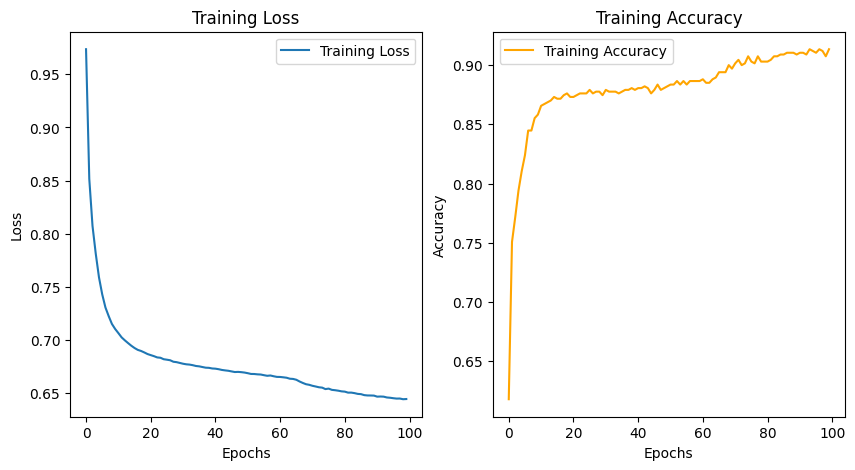

In [ ]:
# Plotting the loss and accuracy curves
plt.figure(figsize=(10, 5))

# Plotting the loss curve
plt.subplot(1, 2, 1)
plt.plot(losses, label='Training Loss')
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plotting the accuracy curve
plt.subplot(1, 2, 2)
plt.plot(accuracies, label='Training Accuracy', color='orange')
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

Evaluate the classifier on test data

In [ ]:
total_samples = 0
correct_predictions = 0
classifier.eval()
for i, (inputs, labels) in enumerate(testloader, 0):
  # get predictions
  y_pred = classifier(inputs)

  # accuracy calculation
  _, predicted = torch.max(y_pred.data, 1) # Get the labels
  total_samples += labels.size(0)
  correct_predictions += (predicted == labels).sum().item()

# Calculate and store accuracy after each epoch
accuracy = correct_predictions / total_samples

# Print stats
print(f'Validation accuracy: {accuracy}')

Validation accuracy: 0.9134328358208955
